# Week 1 — Environment Smoke Test (highway-env)

Verify the local Python environment runs Gymnasium **highway-v0**
(via `highway-env`) without errors (M1 Week-1 task, also covers
M3's baseline recording).

This notebook, in order:
1. Checks the live observation / action spaces against the spec table
2. Runs **5 random-policy episodes**, recording lengths and returns as the baseline
3. Saves **one animated GIF per episode** to `results/videos/`

> Run top-to-bottom. A passing run ends with `smoke test passed`.

In [1]:
from pathlib import Path

import gymnasium as gym
import highway_env  # noqa: F401  (registers highway-v0 with gymnasium)
import imageio
import numpy as np
from IPython.display import Image, display

print("gymnasium:", gym.__version__)
import highway_env
print("highway_env:", highway_env.__version__)
print("imageio:", imageio.__version__)

gymnasium: 1.3.0
highway_env: 1.12.1
imageio: 2.38.0


## 1. highway-v0 specification check

| Item | Spec (default config) |
|---|---|
| Observation | Box(-inf, inf, (5, 5), float32): 5 tracked vehicles x 5 features `[present, x, y, vx, vy]` (flatten to 25 for the network) |
| Action | 5 discrete: `{0: LANE_LEFT, 1: IDLE, 2: LANE_RIGHT, 3: FASTER, 4: SLOWER}` |
| Reward | Speed-based: higher reward near target speed (20 m/s), penalty on collision |
| Episode end | Collision, off-road, or 40 steps (default `duration` at 1 Hz) |

In [2]:
EXPECTED_OBS_SHAPE = (5, 5)  # 5 tracked vehicles x 5 features each
EXPECTED_OBS_DIM = 25        # network input: flattened observation
EXPECTED_ACTION_DIM = 5      # LANE_LEFT, IDLE, LANE_RIGHT, FASTER, SLOWER

env = gym.make("highway-v0", render_mode="rgb_array")

obs_shape = env.observation_space.shape
obs_dim = obs_shape[0] * obs_shape[1]
action_dim = env.action_space.n

print("obs space:  ", env.observation_space)
print("action space:", env.action_space)
print("action meanings:", env.unwrapped.action_type.actions)

assert obs_shape == EXPECTED_OBS_SHAPE, f"obs shape {obs_shape} != {EXPECTED_OBS_SHAPE}"
assert obs_dim == EXPECTED_OBS_DIM, f"obs dim {obs_dim} != {EXPECTED_OBS_DIM}"
assert action_dim == EXPECTED_ACTION_DIM, f"action dim {action_dim} != {EXPECTED_ACTION_DIM}"
print(f"spec check ok: {obs_shape} obs (flatten to {obs_dim}), {action_dim} actions")

obs space:   Box(-inf, inf, (5, 5), float32)
action space: Discrete(5)
action meanings: {0: 'LANE_LEFT', 1: 'IDLE', 2: 'LANE_RIGHT', 3: 'FASTER', 4: 'SLOWER'}
spec check ok: (5, 5) obs (flatten to 25), 5 actions


## 2. Random-policy baseline — 5 episodes, one GIF each

Each episode uses `env.action_space.sample()` (uniform random actions).
The episode lengths and returns are the baseline that trained agents
must beat, and each episode is saved as an animated GIF.

In [3]:
EPISODES = 5
FPS = 10
OUTPUT_DIR = Path("../results/videos")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
def record_episode(env, seed):
    """Run one random-policy episode; return (frames, total_reward, steps)."""
    obs, info = env.reset(seed=seed)
    frames = []
    done = False
    steps = 0
    total_reward = 0.0
    while not done:
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        frame = env.render()
        if frame is not None:
            frames.append(np.asarray(frame))
        steps += 1
        total_reward += reward
    return frames, total_reward, steps

episode 0: 10 steps, return 8.30


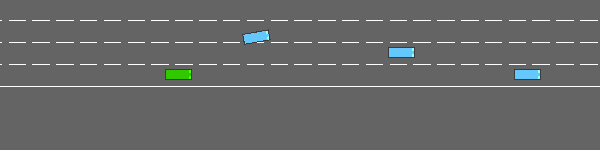

episode 1: 15 steps, return 11.89


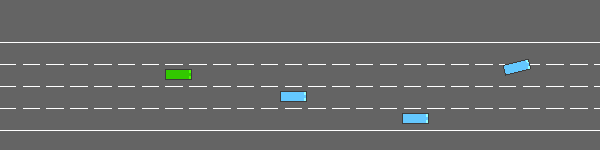

episode 2: 5 steps, return 4.02


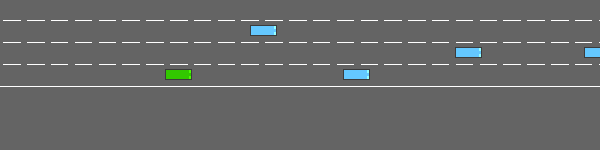

episode 3: 12 steps, return 8.18


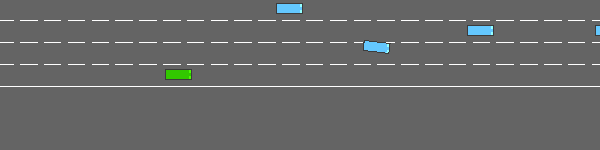

episode 4: 16 steps, return 12.29


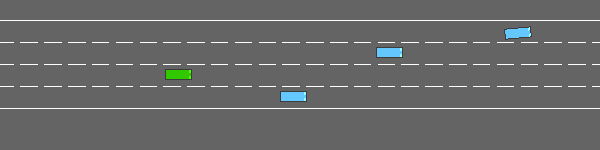

In [5]:
lengths = []
returns = []

for episode in range(EPISODES):
    frames, total_reward, steps = record_episode(env, seed=episode)
    path = OUTPUT_DIR / f"episode_{episode}.gif"
    imageio.mimsave(path, frames, fps=FPS)
    lengths.append(steps)
    returns.append(total_reward)
    print(
        f"episode {episode}: {steps} steps, return {total_reward:.2f}"
    )
    display(Image(filename=str(path)))  # embedded playback, inline in the notebook

env.close()

In [6]:
print(f"random baseline episode lengths: {lengths}")
print(f"random baseline returns:         {[round(r, 2) for r in returns]}")
print(f"mean length: {sum(lengths) / len(lengths):.1f} steps")
print()
for path in sorted(OUTPUT_DIR.glob("episode_*.gif")):
    print(f"{path.name}: {path.stat().st_size / 1024:.0f} KB")
print("smoke test passed")

random baseline episode lengths: [10, 15, 5, 12, 16]
random baseline returns:         [np.float64(8.3), np.float64(11.89), np.float64(4.02), np.float64(8.18), np.float64(12.29)]
mean length: 11.6 steps

episode_0.gif: 11 KB
episode_1.gif: 16 KB
episode_2.gif: 5 KB
episode_3.gif: 13 KB
episode_4.gif: 16 KB
smoke test passed


## Swap in a trained policy (Week 4)

Replace the random action in `record_episode` with the trained policy,
e.g.:

```python
import torch
from src.policy import PolicyNetwork

model = PolicyNetwork(obs_dim=25, n_actions=5)
model.load_state_dict(torch.load("results/models/agent.pt"))

with torch.no_grad():
    probs = model(torch.tensor(obs.reshape(-1), dtype=torch.float32))
action = torch.multinomial(probs, 1).item()
```